# PI-4803 · Gestión de la Innovación
## Práctica de Empatía — Análisis de sentimientos del caso del proyecto
**Versión compatible con Google Colab 2026**

Ejecuta las celdas **en orden, de arriba hacia abajo**.  
Esta versión permite cargar datos directamente desde **Excel (.xlsx)**, **CSV** o **Google Sheets**.

## PASO 1 — Preparar el entorno y cargar los modelos

Esta celda debe terminar mostrando:

- `✅ Utilidades listas`
- `✅ Modelos cargados correctamente`
- `✅ Entorno listo para continuar`

Si reinicias el entorno de Colab, debes volver a ejecutar esta celda.

In [1]:

# ========= ENTORNO COMPATIBLE CON GOOGLE COLAB 2026 =========
# No instalamos pysentimiento como paquete porque su cadena de dependencias
# puede intentar compilar versiones antiguas de "tokenizers" en Python 3.13.
# Usamos directamente los modelos oficiales de pysentimiento desde Hugging Face.

import sys
import subprocess

print("Python:", sys.version)

# Solo instalamos utilidades ligeras que sí necesitamos para exportar.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "gspread", "gspread-dataframe", "XlsxWriter", "reportlab"
])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from types import SimpleNamespace

# Google Sheets
import gspread
from gspread_dataframe import set_with_dataframe
from google.colab import auth
from google.auth import default

# Transformers y Torch ya vienen instalados en Colab.
from transformers import pipeline
import torch

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

print("✅ Utilidades listas.")
print("Torch:", torch.__version__)

# ========= ADAPTADOR DE MODELOS =========
# Mantiene la misma interfaz .predict() que utilizaba el cuaderno original.
class HFAnalyzer:
    def __init__(self, model_name):
        device = 0 if torch.cuda.is_available() else -1
        self.pipe = pipeline(
            task="text-classification",
            model=model_name,
            tokenizer=model_name,
            device=device
        )

    def predict(self, text):
        # top_k=None devuelve todas las clases y sus probabilidades.
        result = self.pipe(
            str(text),
            top_k=None,
            truncation=True,
            max_length=128
        )

        # Compatibilidad con distintas versiones de transformers:
        # para un único texto puede devolver [dict, ...] o [[dict, ...]]
        if result and isinstance(result[0], list):
            result = result[0]

        probas = {item["label"]: float(item["score"]) for item in result}
        output = max(probas, key=probas.get)
        return SimpleNamespace(output=output, probas=probas)

print("⏳ Cargando modelo de sentimiento...")
sentiment_analyzer = HFAnalyzer(
    "pysentimiento/robertuito-sentiment-analysis"
)

print("⏳ Cargando modelo de emociones...")
emotion_analyzer = HFAnalyzer(
    "pysentimiento/robertuito-emotion-analysis"
)

print("✅ Modelos cargados correctamente.")
print("✅ Entorno listo para continuar con el análisis.")


Python: 3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
✅ Utilidades listas.
Torch: 2.14.1+cpu
⏳ Cargando modelo de sentimiento...
⏳ Cargando modelo de emociones...
✅ Modelos cargados correctamente.
✅ Entorno listo para continuar con el análisis.


Device set to use cpu
Device set to use cpu


## PASO 2 — Elegir cómo cargar las respuestas

Para probar con el archivo Excel suministrado, deja:

```python
INPUT_MODE = "xlsx"
```

y ejecuta la celda siguiente. Colab te pedirá seleccionar el archivo `.xlsx`.

In [2]:
# ========= CONFIGURACIÓN DE ENTRADA =========
# Opciones: "xlsx" | "csv" | "sheets"
INPUT_MODE = "xlsx"

# Para Excel:
EXCEL_SHEET_NAME = "Sheet1"

# Para Google Sheets:
GOOGLE_SHEET_URL = "PEGA_AQUI_LA_URL_DE_TU_HOJA_DE_RESPUESTAS"
WORKSHEET_NAME   = "Respuestas"

# Para CSV:
CSV_ENCODING = "utf-8"

# Columna principal de texto.
# Déjala en None para que el cuaderno intente detectar automáticamente la Q3.
TEXT_COLUMN = '¿Cómo describiría, en una sola frase y con sus propias palabras, su experiencia al manejar los desperdicios de comida que se generan diariamente en su hogar?'

TEXT_COLUMN_KEYWORD = "cómo describirías tu experiencia o percepción general"

# Salidas
CSV_OUTPUT_NAME = "respuestas_con_sentimientos.csv"

## PASO 3 — Cargar las respuestas

Al finalizar esta celda debes ver:

`✅ DataFrame df creado correctamente`

y una pequeña vista previa de las respuestas.

**No ejecutes el análisis si esta celda no termina correctamente.**

In [3]:
# ========= CARGA DE DATOS =========
import pandas as pd

if INPUT_MODE == "xlsx":
    from google.colab import files
    print("➡️ Sube el archivo Excel (.xlsx) con las respuestas.")
    uploaded = files.upload()
    xlsx_name = next(iter(uploaded))

    df = pd.read_excel(
        xlsx_name,
        sheet_name=EXCEL_SHEET_NAME
    )
    print(f"➡️ Cargadas {len(df)} filas desde '{xlsx_name}' / hoja '{EXCEL_SHEET_NAME}'")

elif INPUT_MODE == "csv":
    from google.colab import files
    print("➡️ Sube el archivo CSV con las respuestas.")
    uploaded = files.upload()
    csv_name = next(iter(uploaded))

    try:
        df = pd.read_csv(csv_name, encoding=CSV_ENCODING)
    except UnicodeDecodeError:
        print("⚠️ Falló utf-8. Probando latin1...")
        df = pd.read_csv(csv_name, encoding="latin1")

    print(f"➡️ Cargadas {len(df)} filas desde '{csv_name}'")

elif INPUT_MODE == "sheets":
    if "PEGA_AQUI" in GOOGLE_SHEET_URL:
        raise ValueError("Debes pegar la URL de Google Sheets en GOOGLE_SHEET_URL.")

    sh = gc.open_by_url(GOOGLE_SHEET_URL)
    ws = sh.worksheet(WORKSHEET_NAME)

    data = ws.get_all_values()
    if not data:
        raise ValueError("La hoja está vacía.")

    headers = data[0]
    rows = data[1:]

    # Manejo de encabezados duplicados
    cols = []
    col_counts = {}
    for h in headers:
        if h in col_counts:
            col_counts[h] += 1
            cols.append(f"{h}_{col_counts[h]}")
        else:
            col_counts[h] = 0
            cols.append(h)

    df = pd.DataFrame(rows, columns=cols)
    print(f"➡️ Cargadas {len(df)} filas desde Google Sheets: '{WORKSHEET_NAME}'")

else:
    raise ValueError("INPUT_MODE debe ser 'xlsx', 'csv' o 'sheets'.")

# ========= DETECCIÓN DE LA PREGUNTA CLAVE =========
if TEXT_COLUMN is None:
    keyword = TEXT_COLUMN_KEYWORD.lower().strip()
    candidates = [c for c in df.columns if keyword in str(c).lower()]

    if len(candidates) == 1:
        TEXT_COLUMN = candidates[0]
        print(f"✅ Pregunta clave detectada automáticamente:\n{TEXT_COLUMN}")
    elif len(candidates) > 1:
        print("⚠️ Hay varias columnas posibles:")
        for i, c in enumerate(candidates, 1):
            print(f"  {i}. {c}")
        raise ValueError("Define TEXT_COLUMN manualmente en el PASO 2.")
    else:
        print("⚠️ No pude detectar automáticamente la pregunta clave.")
        print("Columnas disponibles:")
        for i, c in enumerate(df.columns, 1):
            print(f"  {i}. {c}")
        raise ValueError(
            "Copia el nombre exacto de la columna Q3 y colócalo en TEXT_COLUMN en el PASO 2."
        )

if TEXT_COLUMN not in df.columns:
    raise ValueError(
        f"No encuentro la columna '{TEXT_COLUMN}'. "
        f"Columnas disponibles: {list(df.columns)}"
    )

# Limpieza
df[TEXT_COLUMN] = df[TEXT_COLUMN].fillna("").astype(str).str.strip()
df = df[df[TEXT_COLUMN] != ""].copy()

print()
print("✅ DataFrame df creado correctamente.")
print(f"✅ Respuestas válidas para analizar: {len(df)}")
print(f"✅ Columna analizada: {TEXT_COLUMN}")

display(df[[TEXT_COLUMN]].head())

➡️ Sube el archivo Excel (.xlsx) con las respuestas.
➡️ Cargadas 32 filas desde 'Respuestas_originales.xlsx' / hoja 'Sheet1'

✅ DataFrame df creado correctamente.
✅ Respuestas válidas para analizar: 32
✅ Columna analizada: ¿Cómo describiría, en una sola frase y con sus propias palabras, su experiencia al manejar los desperdicios de comida que se generan diariamente en su hogar?


,"¿Cómo describiría, en una sola frase y con sus propias palabras, su experiencia al manejar los desperdicios de comida que se generan diariamente en su hogar?"
0,Desagradable
1,Incómodo
2,Sencillo debido a que se pone todo en una bols...
3,Complicado
4,En mi caso yo los boto


## PASO 4 — Ejecutar el análisis automático

Esta celda usa el `df` creado en el **PASO 3**.  
Si aparece un mensaje diciendo que `df` no existe, vuelve al PASO 3 y ejecútalo.

In [4]:
# ========= ANÁLISIS AUTOMÁTICO =========
from tqdm.auto import tqdm

# Comprobaciones para evitar errores por ejecutar celdas fuera de orden
if "df" not in globals():
    raise RuntimeError(
        "❌ No existe el DataFrame 'df'. "
        "Ejecuta primero el PASO 3 — Cargar las respuestas."
    )

if "TEXT_COLUMN" not in globals() or TEXT_COLUMN is None:
    raise RuntimeError(
        "❌ TEXT_COLUMN no está definido. "
        "Ejecuta primero los PASOS 2 y 3."
    )

if "sentiment_analyzer" not in globals() or "emotion_analyzer" not in globals():
    raise RuntimeError(
        "❌ Los modelos no están cargados. "
        "Ejecuta primero el PASO 1."
    )

texts = df[TEXT_COLUMN].fillna("").astype(str).tolist()

sentiment_label = []
sentiment_conf = []
emo_scores = []

print(f"➡️ Analizando {len(texts)} respuestas...")

for txt in tqdm(texts):
    # Sentimiento
    s = sentiment_analyzer.predict(txt)
    sentiment_label.append(s.output)
    sentiment_conf.append(float(max(s.probas.values())))

    # Emociones
    e = emotion_analyzer.predict(txt)
    emo_scores.append(e.probas)

df["sentiment_label"] = sentiment_label
df["confidence"] = sentiment_conf

if emo_scores:
    emo_keys = sorted({k for d in emo_scores for k in d.keys()})
    for k in emo_keys:
        df[f"emo_{k}"] = [float(d.get(k, 0.0)) for d in emo_scores]

print("✅ Análisis terminado.")
print("✅ Columnas agregadas: sentiment_label, confidence y emo_*")
display(df[[TEXT_COLUMN, "sentiment_label", "confidence"]].head())

➡️ Analizando 32 respuestas...
✅ Análisis terminado.
✅ Columnas agregadas: sentiment_label, confidence y emo_*


100%|##########| 32/32 [00:04<00:00,  7.58it/s]


,"¿Cómo describiría, en una sola frase y con sus propias palabras, su experiencia al manejar los desperdicios de comida que se generan diariamente en su hogar?",sentiment_label,confidence
0,Desagradable,NEU,0.477803
1,Incómodo,NEU,0.501772
2,Sencillo debido a que se pone todo en una bols...,NEG,0.931125
3,Complicado,NEU,0.506313
4,En mi caso yo los boto,NEU,0.799101


## PASO 5 — Revisar visualizaciones

Aquí se genera una vista previa del perfil de emociones antes de crear los archivos finales.

In [5]:
if "df" not in globals() or "sentiment_label" not in df.columns:
    raise RuntimeError("❌ Ejecuta primero el PASO 4 — Análisis automático.")


# ========= VISUALIZACIÓN PRELIMINAR MEJORADA =========
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, pi

EMOTION_ES = {
    "joy": "Alegría",
    "trust": "Confianza",
    "fear": "Miedo",
    "surprise": "Sorpresa",
    "sadness": "Tristeza",
    "disgust": "Disgusto",
    "anger": "Enojo",
    "anticipation": "Anticipación",
    "others": "Otros",
    "neutral": "Neutral",
}

CANONICAL = [
    "joy", "trust", "fear", "surprise", "sadness",
    "disgust", "anger", "anticipation", "others", "neutral"
]

def preparar_promedios_emociones(df):
    emo_cols = [c for c in df.columns if c.startswith("emo_")]
    if not emo_cols:
        raise ValueError("No se encontraron columnas que empiecen por 'emo_'.")

    emo_cols = sorted(
        emo_cols,
        key=lambda c: CANONICAL.index(c[4:]) if c[4:] in CANONICAL else 999
    )

    data = (
        df[emo_cols]
        .replace(r"^\s*$", np.nan, regex=True)
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0.0)
    )

    means = data.mean().to_frame("promedio").T
    return emo_cols, means

def radar_plot_from_df(df, title="Perfil promedio de emociones"):
    emo_cols, means = preparar_promedios_emociones(df)

    labels = [EMOTION_ES.get(c[4:], c[4:].capitalize()) for c in emo_cols]
    values = means.iloc[0].astype(float).tolist()

    n = len(values)
    angles = np.linspace(0, 2*np.pi, n, endpoint=False)
    angles_closed = np.concatenate([angles, [angles[0]]])
    values_closed = values + [values[0]]

    # Escala legible pero explícita: redondea el máximo hacia arriba.
    max_value = max(values) if values else 1.0
    radial_max = max(0.4, min(1.0, ceil(max_value * 10) / 10))
    if max_value > radial_max:
        radial_max = min(1.0, ceil(max_value * 10) / 10)

    fig = plt.figure(figsize=(8.5, 8.5))
    ax = plt.subplot(111, polar=True)

    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)

    ax.plot(angles_closed, values_closed, linewidth=2.5, marker="o")
    ax.fill(angles_closed, values_closed, alpha=0.18)

    ax.set_xticks(angles)
    ax.set_xticklabels(labels, fontsize=11)

    ticks = np.linspace(0, radial_max, 5)[1:]
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{t:.0%}" for t in ticks], fontsize=9)
    ax.set_ylim(0, radial_max)
    ax.grid(alpha=0.35)

    for angle, value in zip(angles, values):
        ax.annotate(
            f"{value:.1%}",
            xy=(angle, value),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(title, pad=28, fontsize=16, fontweight="bold")
    fig.text(
        0.5, 0.02,
        f"Promedio de probabilidades por emoción · Escala radial 0–{radial_max:.0%}",
        ha="center", fontsize=9
    )
    plt.tight_layout(rect=[0.03, 0.05, 0.97, 0.95])
    plt.show()

    return fig, means

fig_preview, means_preview = radar_plot_from_df(df)
display(
    means_preview.T
    .rename(columns={"promedio": "Promedio"})
    .assign(Porcentaje=lambda x: (x["Promedio"] * 100).round(1))
)


,Promedio,Porcentaje
emo_joy,0.110740,11.1
emo_fear,0.020898,2.1
emo_surprise,0.033958,3.4
emo_sadness,0.063959,6.4
emo_disgust,0.035962,3.6
emo_anger,0.103503,10.4
emo_others,0.630981,63.1


## PASO 6 — Generar el reporte ejecutivo

La celda final genera los gráficos, el CSV procesado, el Excel y el PDF ejecutivo.

✅ Archivos generados:
 - respuestas_con_sentimientos.csv
 - radar_emociones.png
 - emociones_barras.png
 - sentimientos_distribucion.png
 - sentimientos_resumen.xlsx
 - sentimientos_resumen.pdf


,Emoción,Promedio,Porcentaje
0,Alegría,0.1107,11.1
1,Miedo,0.0209,2.1
2,Sorpresa,0.0340,3.4
3,Tristeza,0.0640,6.4
4,Disgusto,0.0360,3.6
5,Enojo,0.1035,10.4
6,Otros,0.6310,63.1


,Sentimiento,Cantidad,Porcentaje
0,Positivo,2,6.2
1,Neutral,18,56.2
2,Negativo,12,37.5


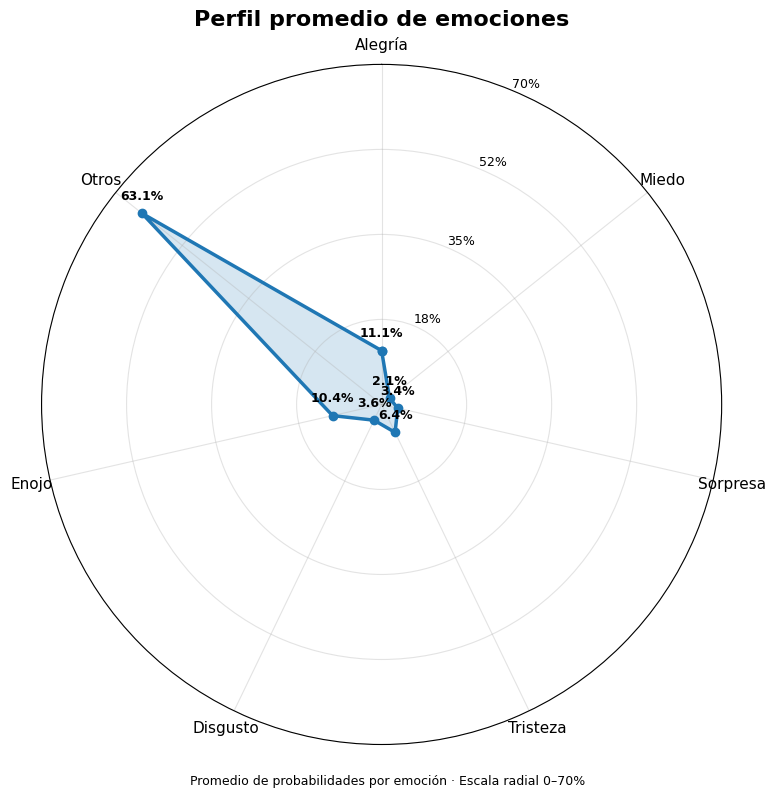

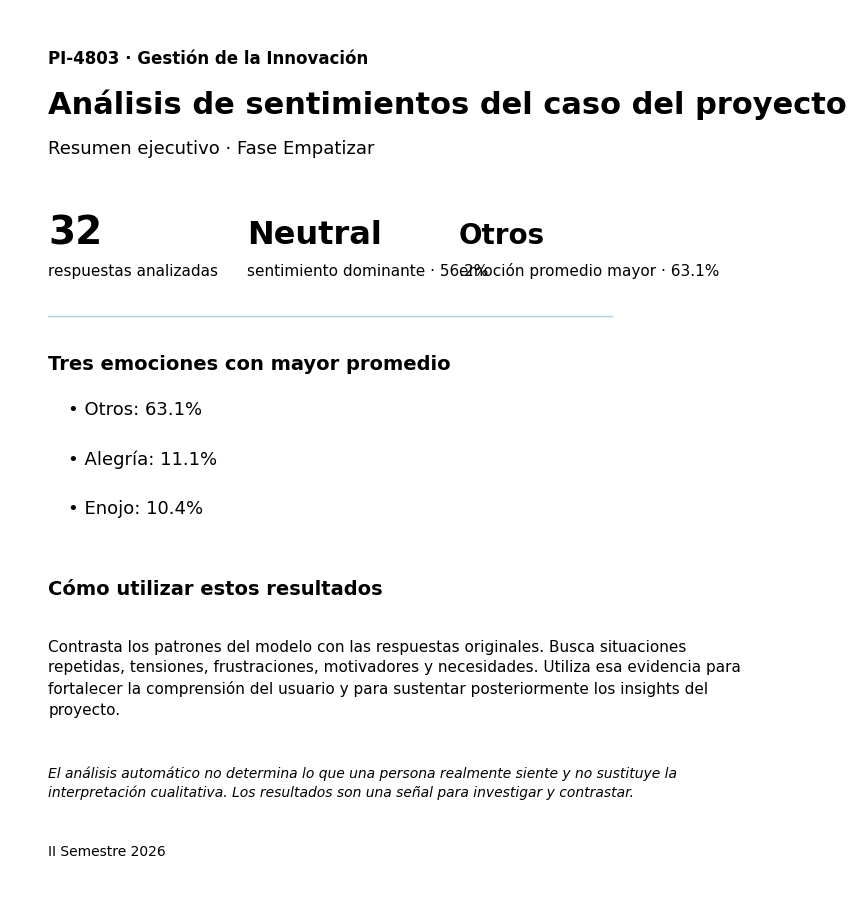

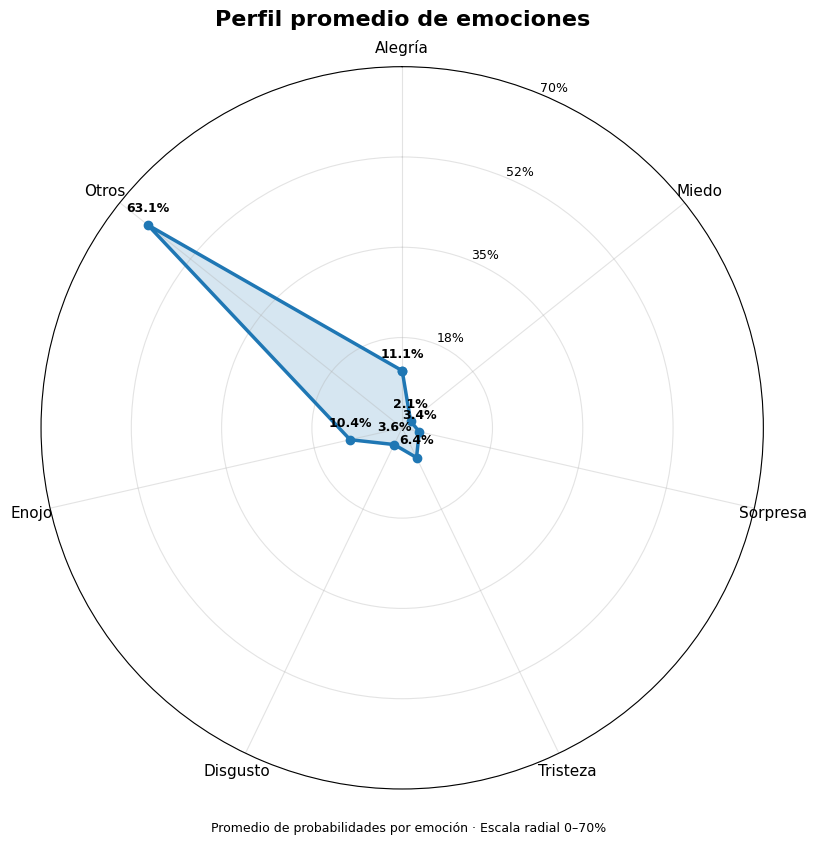

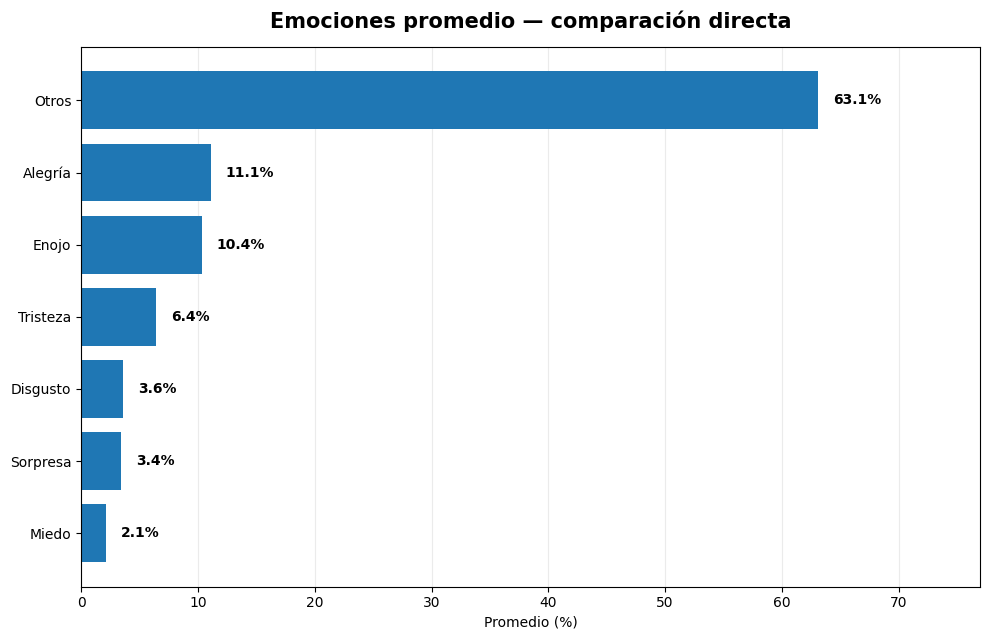

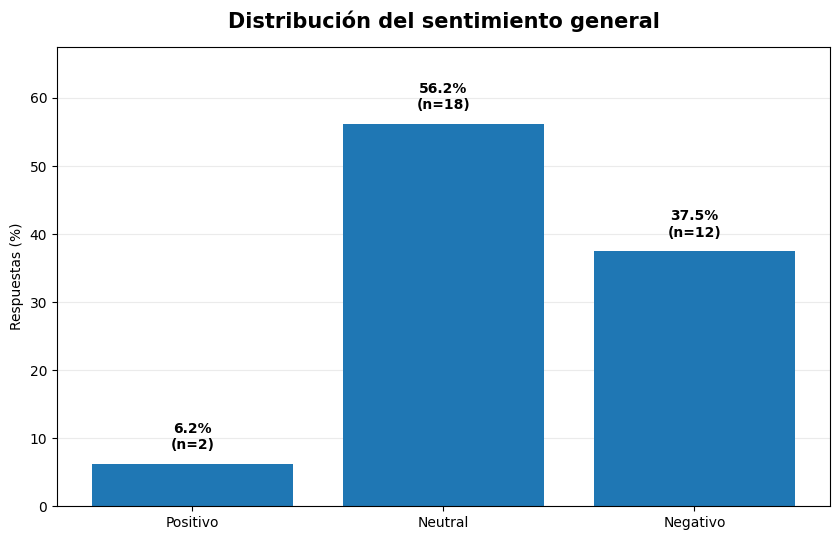

In [6]:
if "df" not in globals() or "sentiment_label" not in df.columns:
    raise RuntimeError("❌ Ejecuta primero el PASO 4 — Análisis automático.")


# ========= REPORTE EJECUTIVO Y EXPORTACIONES =========
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from math import ceil, pi
from textwrap import fill

try:
    from google.colab import files
    IN_COLAB = True
except Exception:
    IN_COLAB = False

EMOTION_ES = {
    "joy": "Alegría",
    "trust": "Confianza",
    "fear": "Miedo",
    "surprise": "Sorpresa",
    "sadness": "Tristeza",
    "disgust": "Disgusto",
    "anger": "Enojo",
    "anticipation": "Anticipación",
    "others": "Otros",
    "neutral": "Neutral",
}

SENTIMENT_ES = {
    "POS": "Positivo",
    "NEG": "Negativo",
    "NEU": "Neutral",
}

CANONICAL = [
    "joy", "trust", "fear", "surprise", "sadness",
    "disgust", "anger", "anticipation", "others", "neutral"
]

# ---------- 1. Preparación ----------
emo_cols = [c for c in df.columns if c.startswith("emo_")]
if not emo_cols:
    raise ValueError("No se encontraron columnas de emociones 'emo_*'.")

emo_cols = sorted(
    emo_cols,
    key=lambda c: CANONICAL.index(c[4:]) if c[4:] in CANONICAL else 999
)

df[emo_cols] = (
    df[emo_cols]
    .replace(r"^\s*$", np.nan, regex=True)
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
)

means = df[emo_cols].mean().to_frame("promedio").T

emotion_summary = means.T.reset_index()
emotion_summary.columns = ["variable", "promedio"]
emotion_summary["emocion"] = emotion_summary["variable"].str.replace("emo_", "", regex=False)
emotion_summary["Emoción"] = emotion_summary["emocion"].map(
    lambda x: EMOTION_ES.get(x, x.capitalize())
)
emotion_summary["Promedio"] = emotion_summary["promedio"].astype(float)
emotion_summary["Porcentaje"] = emotion_summary["Promedio"] * 100
emotion_summary = emotion_summary[["Emoción", "Promedio", "Porcentaje"]]

sentiment_order = ["POS", "NEU", "NEG"]
sentiment_counts = (
    df["sentiment_label"]
    .fillna("SIN_DATO")
    .astype(str)
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

sentiment_summary = sentiment_counts.rename_axis("Código").reset_index(name="Cantidad")
sentiment_summary["Sentimiento"] = sentiment_summary["Código"].map(
    lambda x: SENTIMENT_ES.get(x, x)
)
sentiment_summary["Porcentaje"] = (
    sentiment_summary["Cantidad"] / max(1, sentiment_summary["Cantidad"].sum()) * 100
)
sentiment_summary = sentiment_summary[["Sentimiento", "Cantidad", "Porcentaje"]]

# Indicadores del resumen ejecutivo
n_respuestas = len(df)

dom_sent_row = sentiment_summary.loc[sentiment_summary["Cantidad"].idxmax()]
sentimiento_dominante = dom_sent_row["Sentimiento"]
sentimiento_pct = float(dom_sent_row["Porcentaje"])

dom_emo_row = emotion_summary.loc[emotion_summary["Promedio"].idxmax()]
emocion_dominante = dom_emo_row["Emoción"]
emocion_pct = float(dom_emo_row["Porcentaje"])

top3_emociones = emotion_summary.sort_values("Promedio", ascending=False).head(3)

# ---------- 2. Radar ----------
def crear_radar(emotion_summary, title="Perfil promedio de emociones"):
    labels = emotion_summary["Emoción"].tolist()
    values = emotion_summary["Promedio"].astype(float).tolist()

    n = len(values)
    angles = np.linspace(0, 2*np.pi, n, endpoint=False)
    angles_closed = np.concatenate([angles, [angles[0]]])
    values_closed = values + [values[0]]

    max_value = max(values) if values else 1.0
    radial_max = max(0.4, min(1.0, ceil(max_value * 10) / 10))
    if max_value > radial_max:
        radial_max = min(1.0, ceil(max_value * 10) / 10)

    fig = plt.figure(figsize=(9, 9))
    ax = plt.subplot(111, polar=True)
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)

    ax.plot(angles_closed, values_closed, linewidth=2.5, marker="o")
    ax.fill(angles_closed, values_closed, alpha=0.18)

    ax.set_xticks(angles)
    ax.set_xticklabels(labels, fontsize=11)

    ticks = np.linspace(0, radial_max, 5)[1:]
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{t:.0%}" for t in ticks], fontsize=9)
    ax.set_ylim(0, radial_max)
    ax.grid(alpha=0.35)

    for angle, value in zip(angles, values):
        ax.annotate(
            f"{value:.1%}",
            xy=(angle, value),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_title(title, pad=30, fontsize=16, fontweight="bold")
    fig.text(
        0.5, 0.02,
        f"Promedio de probabilidades por emoción · Escala radial 0–{radial_max:.0%}",
        ha="center", fontsize=9
    )
    plt.tight_layout(rect=[0.03, 0.05, 0.97, 0.95])
    return fig

# ---------- 3. Barras de emociones ----------
def crear_barras_emociones(emotion_summary):
    plot_df = emotion_summary.sort_values("Promedio", ascending=True).copy()

    fig, ax = plt.subplots(figsize=(10, 6.5))
    bars = ax.barh(plot_df["Emoción"], plot_df["Porcentaje"])
    ax.set_title("Emociones promedio — comparación directa", fontsize=15, fontweight="bold", pad=14)
    ax.set_xlabel("Promedio (%)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    max_pct = max(1.0, plot_df["Porcentaje"].max())
    ax.set_xlim(0, max_pct * 1.22)

    for bar, value in zip(bars, plot_df["Porcentaje"]):
        ax.text(
            bar.get_width() + max_pct * 0.02,
            bar.get_y() + bar.get_height()/2,
            f"{value:.1f}%",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    plt.tight_layout()
    return fig

# ---------- 4. Distribución de sentimientos ----------
def crear_barras_sentimientos(sentiment_summary):
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    bars = ax.bar(sentiment_summary["Sentimiento"], sentiment_summary["Porcentaje"])

    ax.set_title("Distribución del sentimiento general", fontsize=15, fontweight="bold", pad=14)
    ax.set_ylabel("Respuestas (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, max(10, sentiment_summary["Porcentaje"].max() * 1.2))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    for bar, pct, n in zip(
        bars,
        sentiment_summary["Porcentaje"],
        sentiment_summary["Cantidad"]
    ):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + max(1, sentiment_summary["Porcentaje"].max()*0.03),
            f"{pct:.1f}%\n(n={int(n)})",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

    plt.tight_layout()
    return fig

# ---------- 5. Portada / resumen ejecutivo ----------
def crear_resumen_ejecutivo():
    fig, ax = plt.subplots(figsize=(8.27, 11.69))
    ax.axis("off")

    ax.text(
        0.06, 0.94,
        "PI-4803 · Gestión de la Innovación",
        fontsize=12, fontweight="bold", transform=ax.transAxes
    )
    ax.text(
        0.06, 0.885,
        "Análisis de sentimientos del caso del proyecto",
        fontsize=22, fontweight="bold", transform=ax.transAxes
    )
    ax.text(
        0.06, 0.84,
        "Resumen ejecutivo · Fase Empatizar",
        fontsize=13, transform=ax.transAxes
    )

    # Indicadores
    ax.text(0.06, 0.74, f"{n_respuestas}", fontsize=28, fontweight="bold", transform=ax.transAxes)
    ax.text(0.06, 0.705, "respuestas analizadas", fontsize=11, transform=ax.transAxes)

    ax.text(0.37, 0.74, sentimiento_dominante, fontsize=23, fontweight="bold", transform=ax.transAxes)
    ax.text(0.37, 0.705, f"sentimiento dominante · {sentimiento_pct:.1f}%", fontsize=11, transform=ax.transAxes)

    ax.text(0.70, 0.74, emocion_dominante, fontsize=20, fontweight="bold", transform=ax.transAxes)
    ax.text(0.70, 0.705, f"emoción promedio mayor · {emocion_pct:.1f}%", fontsize=11, transform=ax.transAxes)

    ax.axhline(0.66, xmin=0.06, xmax=0.94, linewidth=1, alpha=0.35)

    ax.text(0.06, 0.60, "Tres emociones con mayor promedio", fontsize=14, fontweight="bold", transform=ax.transAxes)
    y = 0.55
    for _, row in top3_emociones.iterrows():
        ax.text(
            0.09, y,
            f"• {row['Emoción']}: {row['Porcentaje']:.1f}%",
            fontsize=13, transform=ax.transAxes
        )
        y -= 0.055

    ax.text(0.06, 0.35, "Cómo utilizar estos resultados", fontsize=14, fontweight="bold", transform=ax.transAxes)
    uso = (
        "Contrasta los patrones del modelo con las respuestas originales. "
        "Busca situaciones repetidas, tensiones, frustraciones, motivadores y necesidades. "
        "Utiliza esa evidencia para fortalecer la comprensión del usuario y para sustentar "
        "posteriormente los insights del proyecto."
    )
    ax.text(
        0.06, 0.30, fill(uso, 92),
        fontsize=11, linespacing=1.45, va="top", transform=ax.transAxes
    )

    advertencia = (
        "El análisis automático no determina lo que una persona realmente siente y no sustituye "
        "la interpretación cualitativa. Los resultados son una señal para investigar y contrastar."
    )
    ax.text(
        0.06, 0.16, fill(advertencia, 92),
        fontsize=10, style="italic", linespacing=1.4, va="top", transform=ax.transAxes
    )

    ax.text(0.06, 0.06, "II Semestre 2026", fontsize=10, transform=ax.transAxes)
    return fig

fig_resumen = crear_resumen_ejecutivo()
fig_radar = crear_radar(emotion_summary)
fig_emociones = crear_barras_emociones(emotion_summary)
fig_sentimientos = crear_barras_sentimientos(sentiment_summary)

display(emotion_summary.round({"Promedio": 4, "Porcentaje": 1}))
display(sentiment_summary.round({"Porcentaje": 1}))
plt.show()

# ---------- 6. Archivos de imagen ----------
radar_path = "radar_emociones.png"
bar_path = "emociones_barras.png"
sent_path = "sentimientos_distribucion.png"

fig_radar.savefig(radar_path, dpi=300, bbox_inches="tight")
fig_emociones.savefig(bar_path, dpi=300, bbox_inches="tight")
fig_sentimientos.savefig(sent_path, dpi=300, bbox_inches="tight")

# ---------- 7. CSV con resultados ----------
df.to_csv(CSV_OUTPUT_NAME, index=False, encoding="utf-8-sig")

# ---------- 8. Excel ----------
excel_path = "sentimientos_resumen.xlsx"

with pd.ExcelWriter(excel_path, engine="xlsxwriter") as writer:
    df.to_excel(writer, sheet_name="Respuestas", index=False)
    emotion_summary.to_excel(writer, sheet_name="Promedios", index=False)
    sentiment_summary.to_excel(writer, sheet_name="Sentimientos", index=False)

    wb = writer.book

    ws_radar = wb.add_worksheet("Radar")
    writer.sheets["Radar"] = ws_radar
    ws_radar.set_column("A:A", 3)
    ws_radar.insert_image("B2", radar_path, {"x_scale": 0.78, "y_scale": 0.78})

    ws_visual = wb.add_worksheet("Resumen_visual")
    writer.sheets["Resumen_visual"] = ws_visual
    ws_visual.set_column("A:A", 3)
    ws_visual.insert_image("B2", bar_path, {"x_scale": 0.78, "y_scale": 0.78})
    ws_visual.insert_image("B34", sent_path, {"x_scale": 0.78, "y_scale": 0.78})

# ---------- 9. PDF ejecutivo ----------
pdf_path = "sentimientos_resumen.pdf"

with PdfPages(pdf_path) as pp:
    pp.savefig(fig_resumen, bbox_inches="tight")
    pp.savefig(fig_radar, bbox_inches="tight")
    pp.savefig(fig_emociones, bbox_inches="tight")
    pp.savefig(fig_sentimientos, bbox_inches="tight")

    # Tabla de emociones
    fig_tbl, ax_tbl = plt.subplots(figsize=(8.27, 11.69))
    ax_tbl.axis("off")
    tbl_df = emotion_summary[["Emoción", "Porcentaje"]].copy()
    tbl_df["Porcentaje"] = tbl_df["Porcentaje"].map(lambda x: f"{x:.1f}%")
    table = ax_tbl.table(
        cellText=tbl_df.values,
        colLabels=tbl_df.columns,
        loc="center",
        cellLoc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1, 1.5)
    ax_tbl.set_title("Promedios por emoción", pad=24, fontsize=16, fontweight="bold")
    pp.savefig(fig_tbl, bbox_inches="tight")
    plt.close(fig_tbl)

plt.close(fig_resumen)
plt.close(fig_radar)
plt.close(fig_emociones)
plt.close(fig_sentimientos)

print("✅ Archivos generados:")
for path in [
    CSV_OUTPUT_NAME,
    radar_path,
    bar_path,
    sent_path,
    excel_path,
    pdf_path
]:
    print(" -", path)

# ---------- 10. Descarga ----------
if IN_COLAB:
    for path in [
        CSV_OUTPUT_NAME,
        radar_path,
        bar_path,
        sent_path,
        excel_path,
        pdf_path
    ]:
        files.download(path)


## Interpretación para el proyecto

Después de generar los archivos, contrasta los patrones automáticos con las respuestas originales:

1. ¿Qué sentimiento general predomina?
2. ¿Cuáles emociones aparecen con mayor fuerza?
3. ¿Qué frases concretas ayudan a explicar esos resultados?
4. ¿Qué tensión, frustración, motivador o necesidad parece repetirse?
5. ¿Qué hallazgo conviene conservar como evidencia para la fase de definición?

Usa formulaciones prudentes, por ejemplo: **“El análisis sugiere un patrón que también se observa en…”**